In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal
from src.summary import summary

In [ ]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [ ]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)
momentum_signal = generate_momentum_signal(prices, lookback)
momentum_position = momentum_df["position"]

#### Cyclic-Shifting Exploration

In [ ]:
x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

group_1 = []
group_2 = []

for i in range(lookback + 1, len(momentum_position)):

    if i < x:
        group_1.append(momentum_position.iloc[i])
    elif i >= x:
        group_2.append(momentum_position.iloc[i])

In [ ]:
sequence = []

sequence.extend(group_2)
sequence.extend(group_1)

sequence.append(np.nan)
random_signal = ([np.nan] * lookback) + sequence

sequence


In [ ]:
random_df, random_result = backtester(returns, random_signal, 0.001)
random_df.iloc[250:260]

In [ ]:
one_count = 0
zero_count = 0

for i in range(len(sequence)):
    if sequence[i] == 1:
        one_count += 1
    elif sequence[i] == 0:
        zero_count += 1

print(one_count)
print(zero_count)

In [ ]:
run_boundaries = []

for i in range(1, len(sequence)):
    if sequence[i] != sequence[i - 1]:
        run_boundaries.append(i)

len(run_boundaries)

#### Cyclic-Shifting Function Definition

In [31]:
def generate_random_signal_v6(momentum_position, lookback):

    x = np.random.choice(np.arange(lookback + 1, len(momentum_position)), replace = False)

    group_1 = momentum_position.iloc[lookback + 1: x]
    group_2 = momentum_position.iloc[x:]

    sequence = []

    sequence.extend(group_2)
    sequence.extend(group_1)

    sequence.append(np.nan)
    random_signal = ([np.nan] * lookback) + sequence  

    return random_signal 

In [32]:
def run_simulation_v5(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v6(momentum_position, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [36]:
np.random.seed(44)

simulation_output = run_simulation_v5(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.640932,0.051702,0.177454,0.372883,-0.551895,0.093680,0.775232,91
1,3.560960,0.060985,0.174772,0.426198,-0.568759,0.107225,0.775232,91
2,4.075854,0.065421,0.172471,0.453732,-0.605594,0.108028,0.775232,91
3,11.767719,0.104457,0.154446,0.720748,-0.337173,0.309802,0.775232,91
4,3.817706,0.063254,0.173120,0.440884,-0.543644,0.116352,0.775232,91
...,...,...,...,...,...,...,...,...
99995,2.334953,0.048106,0.175325,0.355717,-0.556776,0.086402,0.775232,90
99996,3.180478,0.057386,0.176889,0.403943,-0.557243,0.102982,0.775232,90
99997,2.297147,0.047640,0.162047,0.368266,-0.460290,0.103501,0.775232,91
99998,6.238620,0.080276,0.154416,0.577465,-0.363894,0.220602,0.775232,91


Sharpe Average: 0.4735
Sharpe Median:  0.4424
Largest Sharpe: 1.1811
Average No. of Trades: 90.7622
Average Time Invested: 0.7752
Empirical p-value: 0.11016


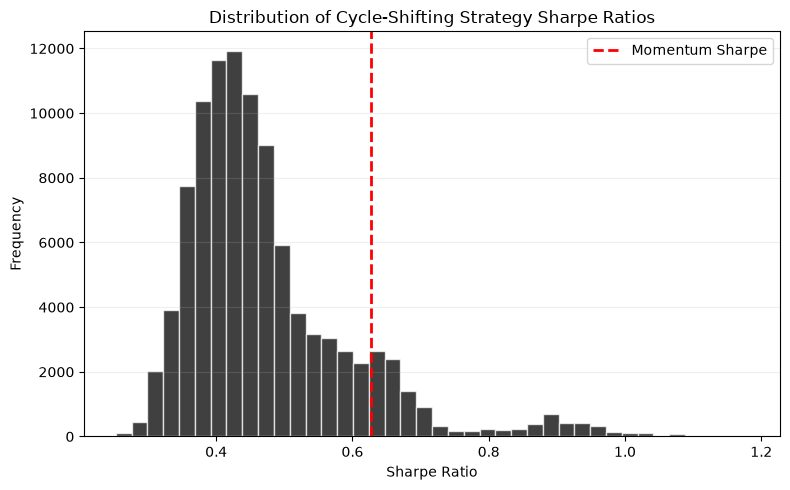

In [38]:
summary(simulation_df, momentum_results, "Distribution of Cycle-Shifting Strategy Sharpe Ratios")

In [22]:
%%timeit

for i in range(lookback + 1, len(momentum_position)):

    if i < x:
        group_1.append(momentum_position.iloc[i])
    elif i >= x:
        group_2.append(momentum_position.iloc[i])

10.9 ms ± 21.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [24]:
%%timeit

group_1 = momentum_position.iloc[lookback + 1: x - 1]
group_2 = momentum_position.iloc[x:]

8.57 μs ± 32.9 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
